##### Health Information Systems and Decision Support Systems
## WPO 3: Data-driven systems 1: Regression  (07/03/25)
***
*Jakub Ceranka, Joris Wuts, Pieter Boonen, Jef Vandemeulebroucke* <br>
*Department of Electronics and Informatics (ETRO)* <br>
*Vrije Universiteit Brussel, Pleinlaan 2, B-1050 Brussels, Belgium*

<font color=blue>Insert students names and IDs here</font>

Seyed Hossein Mohammadi
-
ID: 0610734

***
### Goal
The goal of this practical session is to get an insight into logistic regression modelling using real life medical data from patients infected with COVID-19. Your tasks will involve building different models to predict disease severity and analyze the relations between different variables and severity risk. Students must send their notebook using the Assignment functionality in Canvas before the __13th of March, 2025, 23:59. Remember to include the HTML format!__ The grade from this practical session will contribute to your final grade.

Questions: on the discusion channel on Teams and your Breakout Room
***
In this practical session you will predict the severity of the COVID-19 outcome, based on the analysis of patient information and the corresponding computed tomography (CT) images features of COVID-19 suspects and actual patients suffering from COVID-19.
***
#### COVID features dataset
Have a look at the provided COVID datasheet (*COVID_data.csv*) with multiple features describing various COVID patients and suspects. The dataset consist of 2000 data points with multiple features, each datapoint representing an actual COVID-patient or a COVID-suspect.

The contents of the feaures provide the following information:
*   *PatientID*: ID of the patient
*   *Age*: Age of the patient categorized into one of 6 categories to limit the risk of deanonimization.
*   *Sex*: M or F - patient gender
*   *Covid*: Indicates whether the patient had a confirmed COVID infection
*   *Severity*: For COVID patients, indicates whether the disease was severe (need for intubation or caused patient death)
*   *Image_size* and *Spacing* are CT image parameters used for imaging
*   *GGO*: Proportion of the lung with GGO. Ground glass opacity (*GGO*) refers to the hazy gray areas that can show up in CT scans or X-rays of the lungs. These gray areas indicate increased density inside the lungs. The term comes from a technique in glassmaking during which the surface of the glass is blasted by sand.
*   *Consolidation*: Proportion of the lung with consolidated lessions. A pulmonary consolidation is a region of normally compressible lung tissue that has filled with liquid instead of air.

Two last features (*GGO* and *Consolidation*) were extracted from CT images of patients with COVID, or suspects of having COVID, and the ratio to the total lung volume is provided.

<img src="GGO.jpeg" alt="Drawing" style="width: 600px;"/>

High-resolution CT image showing ground-glass opacities in the periphery of both lungs in a patient with COVID-19 (red arrows). The adjacent normal lung tissue with lower attenuation appears as darker areas.


### Importing packages

During this lab session you will need a couple of packages, run the following cell to import pandas, numpy, seaborn and matplotlib.

In [27]:
# !pip install statkit

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

***
## Part 1: Loading, cleaning and analyzing the data
### Task 1.1 Loading and cleaning the data
Lets read the data into the dataframe `data`.

Inspect the dataframe and drop the following columns : `Images_sizes, Spacings, PatientID`.

Your processed dataframe should have a shape of `(2000,6)`.

Please call your final dataframe `df` throughout the whole lab session, as we provide code snipets in Task 2 and 3 that assume this variable name for the dataframe.

To further use the dataframe, we need to binarize the `Sex` label. Binarize the column so that male patients have a value of 1 and females of 0. Finally, filter the dataframe so it only has COVID positive patients. After filtering you can also drop the COVID column.

Your final dataframe should be a shape of `(1205, 5)`.

In [29]:
# Your code here
# Load data
data = pd.read_csv('COVID_data.csv')

# Drop unnecessary columns
df = data.drop(
    columns=['Image_size_x', 'Image_size_y', 'Image_size_z', 'Spacing_x', 'Spacing_y', 'Spacing_z', 'PatientID'])

# Binarize 'Sex' (Male=1, Female=0)
df['Sex'] = df['Sex'].map({'M': 1, 'F': 0})

# Filter COVID-positive patients and drop the 'Covid' column
df = df[df['Covid'] == 1].drop(columns='Covid')

# Verify final shape
print(df.shape)

(1205, 5)


***
### Task 1.2: Assess the severity of COVID-19 in function of age

Plot a histogram for the different age groups. Note, that the ages are categorical at 6 fixed values.

__Hint:__ Use seaborns `histplot`.

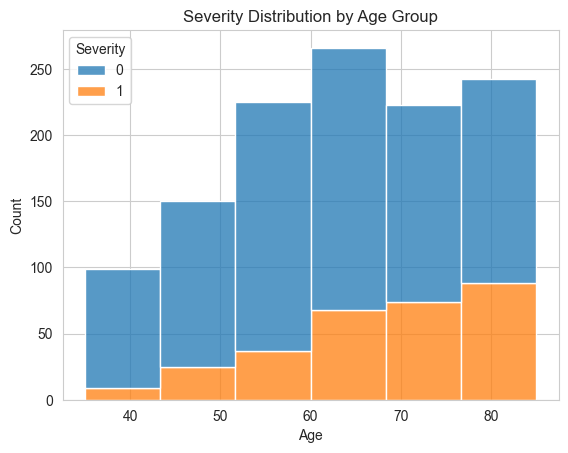

In [30]:
# Your code here
# Plot histogram for Age vs Severity
sns.histplot(data=df, x='Age', hue='Severity', bins=6, multiple='stack')
plt.title('Severity Distribution by Age Group')
plt.show()

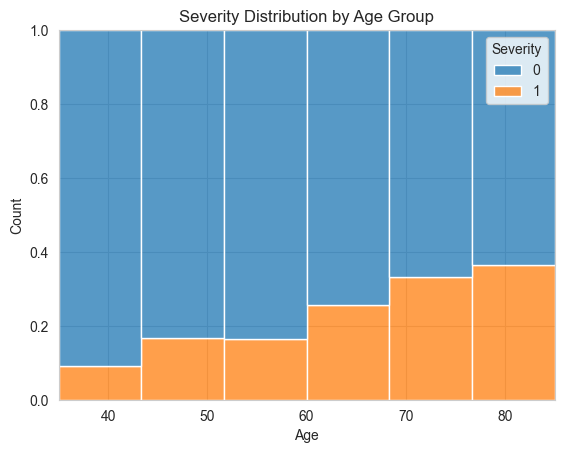

In [31]:
# Your code here
# Plot histogram for Age vs Severity normalised counts for both classes of Severity
sns.histplot(data=df, x='Age', hue='Severity', multiple='fill', bins=6)
plt.title('Severity Distribution by Age Group')
plt.show()

### Question 1.1: What can you conclude from this plots?

Answer to question 1.1: less that 40% of the patients have high severity, and of these, the older patients seem to be more likly. for example, people at their 80s are 4 times more likely t be serverly affected than people at their 40s.
also, there are more people infected in their 60s and 70s relative to other age groups.

***
### Task 1.3: Checking the impact of GGO, consolidation and sex on the COVID severity

Now make similar two kde plots to assess the correlations between the `GGO`, `Consolidation` vs `Severity`.

To assess the impact of `sex`  we will use a different plot. Use a scatter plot to plot the mean fraction of severity per age group. Use 2 different colours for male and female patients.

__Hint__: Split the dataframe into 2 new dataframes containing only 1 sex. Then use the groupby functionality to agregate information per age group. Use categorical points instead of continous plot.

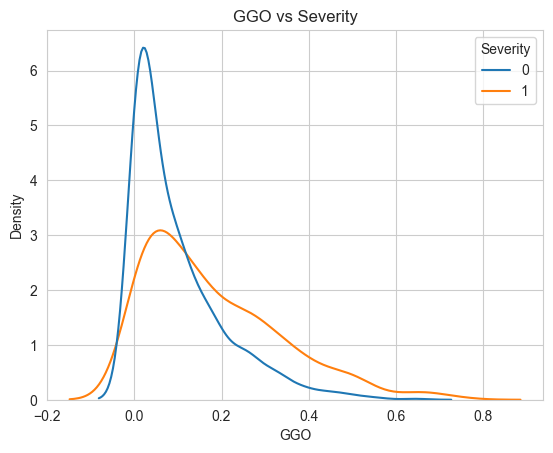

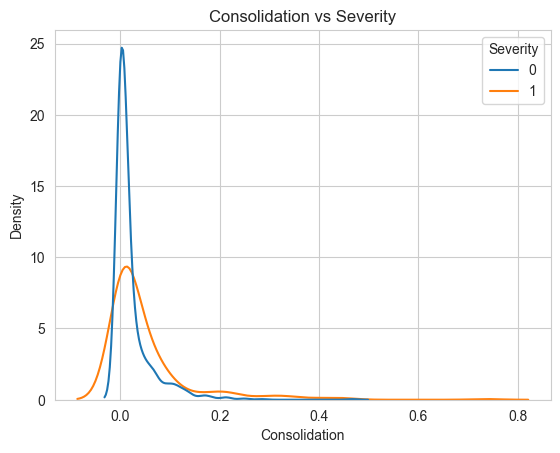

In [32]:
# GGO vs Severity plot
# KDE plots for GGO and Consolidation
sns.kdeplot(data=df, x='GGO', hue='Severity', common_norm=False)
plt.title('GGO vs Severity')
plt.show()

sns.kdeplot(data=df, x='Consolidation', hue='Severity', common_norm=False)
plt.title('Consolidation vs Severity')
plt.show()

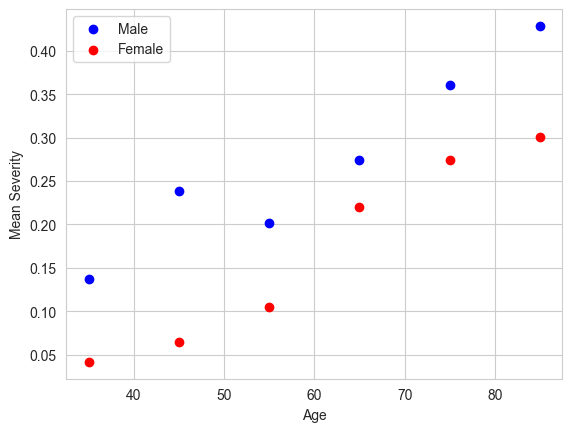

In [33]:
# Scatter plot for Sex vs Severity (grouped by Age)
df_male = df[df['Sex'] == 1]
df_female = df[df['Sex'] == 0]

male_means = df_male.groupby('Age')['Severity'].mean().reset_index()
female_means = df_female.groupby('Age')['Severity'].mean().reset_index()

plt.scatter(male_means['Age'], male_means['Severity'], color='blue', label='Male')
plt.scatter(female_means['Age'], female_means['Severity'], color='red', label='Female')
plt.xlabel('Age')
plt.ylabel('Mean Severity')
plt.legend()
plt.show()

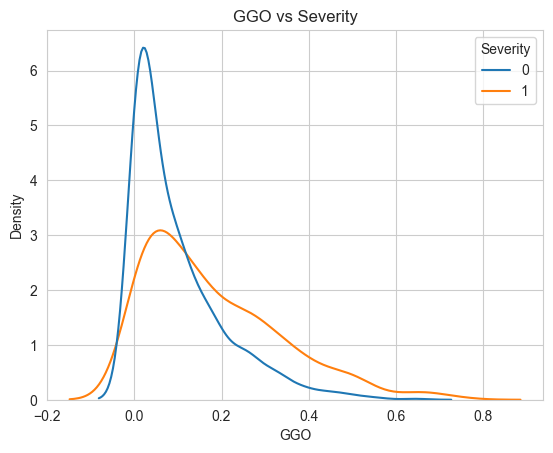

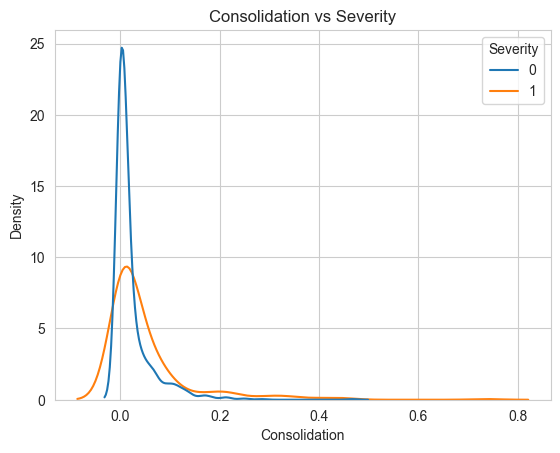

In [34]:
# Consolidation vs Severity plot
# KDE plots for GGO and Consolidation
sns.kdeplot(data=df, x='GGO', hue='Severity', common_norm=False)
plt.title('GGO vs Severity')
plt.show()

sns.kdeplot(data=df, x='Consolidation', hue='Severity', common_norm=False)
plt.title('Consolidation vs Severity')
plt.show()


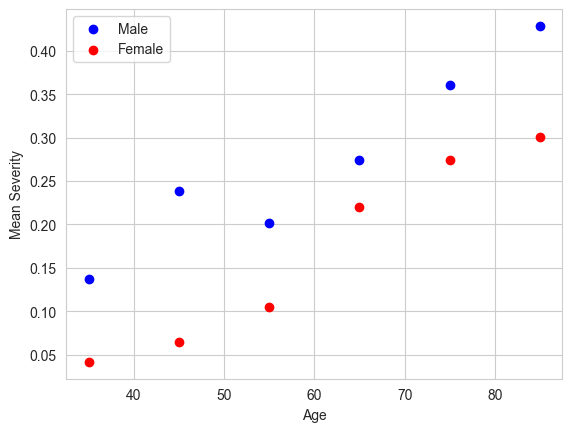

In [35]:
# Sex vs Severity plot
# Scatter plot for Sex vs Severity (grouped by Age)
df_male = df[df['Sex'] == 1]
df_female = df[df['Sex'] == 0]

male_means = df_male.groupby('Age')['Severity'].mean().reset_index()
female_means = df_female.groupby('Age')['Severity'].mean().reset_index()

plt.scatter(male_means['Age'], male_means['Severity'], color='blue', label='Male')
plt.scatter(female_means['Age'], female_means['Severity'], color='red', label='Female')
plt.xlabel('Age')
plt.ylabel('Mean Severity')
plt.legend()
plt.show()

### Question 1.2: What can you say about the relations of `Consolidation`, `GGO` and `Sex` with the `Severity` of COVID?

Answer to Question 1.2: when GGO and Consolidation is higher, its more likly to be a severe case. But there are more severe cases without the 2 being high. Also, men seem to have a higher (mean) severity in all ages with an abnormal spike if they are in their 50s.


***
## Part 2:  Logistic regression of severity on `Age` and `Gender`

Logistic regression allows us to analyze how a set of features affects some binary target label. The weights gives us an estimation of the influence of each particular feature on the probability of the target being equal to one.

We want to model how the probability that a person develops a severe COVID disease is affected by his/her age, sex, and size lung lesions.

Let $y_i = 1$ if i-th person's develop severe symptoms.
Logistic regression models this probabilty in the following way:

\begin{equation}
p(y_i = 1 \mid \beta) = \sigma (\alpha + \beta_0 age_i + \beta_1 sex_i + \dots ),
\end{equation}

where $\sigma(t) = \frac1{1 + e^{-t}}$

We can obtain a point estimate for the intercept $\alpha$ and coefficients $\beta_k$ using *sklearn* package.


### Task 2.1: Define the logistic function

To compute probabilities with the logistic regresion, we first need to define the logistic functions. Use `numpy` and complete the code function below so it returns the logistic function $\sigma(t) = \frac1{1 + e^{-t}}$.

Test your system. The `logistic(1)` should return a value of `+- 0.731`.

In [36]:
def logistic(x):
    return 1 / (1 + np.exp(-x))


# Test
print(logistic(1))

0.7310585786300049


### Task 2.2: Fit a logistic regresion model.
Now lets fit a logistic regression model for COVID severity. This first basic model will only consider two features. We thus have to create a feature set ```X``` by only selecting the ```age``` and ```sex``` columns of the total ```df```. Make sure that age is the first feature column during the whole lab session! Use the logistic regression model (with all default parameters) of ```scikit-learn``` to create and fit the model. Then, print the values of coefficients and the interception of the fitted model.

In [37]:
from sklearn.linear_model import LogisticRegression

X = df[['Age', 'Sex']]
y = df['Severity']

model = LogisticRegression().fit(X, y)
print('Coefficients:', model.coef_)
print('Intercept:', model.intercept_)

Coefficients: [[0.03390489 0.59227295]]
Intercept: [-3.71307422]


### Question 2.1: What do the coefficients and interceptions mean ?

Coefficients: Increase in Age or Sex (male) raises the (log-)odds of severity.

Intercept: Baseline (log-)odds when all predictors are zero.

### Task 2.3: Computing severity risks with the obtained model
Now manually compute the probability of severity with the obtained coefficients. Use your own defined logistic function and the formula presented in task 2.1. Compare the probability of severe disease  of the following patients:
- 60y old male
- 50y old woman.
- 35y old male
- 40y old woman


__Hint__: Represent all features in one numpy array with shape 4 ( patients) by 2 (features). Can you re write the Formula given in task 2 as a Matrix multiplication? A matrix multiplicatoin can be performed by the '@' operation on numpy arrays, Transprosing matrixes with '.T' can also be usefull!


In [38]:
#Your Code here
patients = np.array([[60, 1], [50, 0], [35, 1], [40, 0]])
logits = model.intercept_ + patients @ model.coef_.T
probabilities = logistic(logits)

print('Probabilities (%):', probabilities.flatten().round(3) * 100)

Probabilities (%): [25.2 11.7 12.6  8.7]


### Task 2.4: Plotting severity curves
In task 1.3, you were asked to plot the mean severity for different ages per gender in a scatter plot. In task 2.3, you got probabilities of severity for specific `age` and `sex` combinations. Now print 2 curves representing the probability of having severe COVID per `age` for all ages between 20 and 100. On the same plot, also plot the results obtained from task 1.3.

__Hint__: Manually define `X`.

__Hint__: Use `np.linspace` to contstruct an array of all possible ages between 20 and 100.

__Hint__: `np.vstack` can be usefull to concatenate 2 numpy arrays. You can use it to construct `X`.

__Hint__: Create an `X` matrix representing males, and a seperate `X` matrix for females. You can then easily plot them in different colours


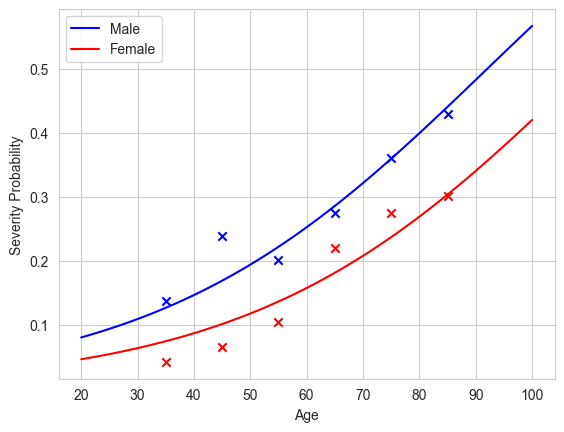

In [39]:
#Your code here
ages = np.linspace(20, 100, 100)
X_male = np.vstack([ages, np.ones(ages.shape)]).T
X_female = np.vstack([ages, np.zeros(ages.shape)]).T

probs_male = logistic(model.intercept_ + X_male @ model.coef_.T)
probs_female = logistic(model.intercept_ + X_female @ model.coef_.T)

plt.plot(ages, probs_male, color='blue', label='Male')
plt.plot(ages, probs_female, color='red', label='Female')
plt.scatter(male_means['Age'], male_means['Severity'], color='blue', marker='x')
plt.scatter(female_means['Age'], female_means['Severity'], color='red', marker='x')
plt.xlabel('Age')
plt.ylabel('Severity Probability')
plt.legend()
plt.show()

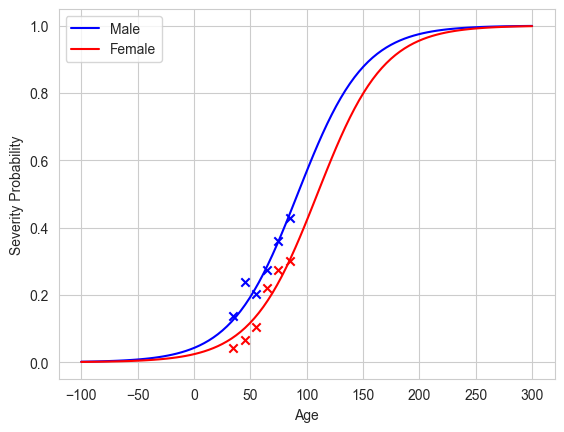

In [40]:
#Your code here
ages = np.linspace(-100, 300, 100)
X_male = np.vstack([ages, np.ones(ages.shape)]).T
X_female = np.vstack([ages, np.zeros(ages.shape)]).T

probs_male = logistic(model.intercept_ + X_male @ model.coef_.T)
probs_female = logistic(model.intercept_ + X_female @ model.coef_.T)

plt.plot(ages, probs_male, color='blue', label='Male')
plt.plot(ages, probs_female, color='red', label='Female')
plt.scatter(male_means['Age'], male_means['Severity'], color='blue', marker='x')
plt.scatter(female_means['Age'], female_means['Severity'], color='red', marker='x')
plt.xlabel('Age')
plt.ylabel('Severity Probability')
plt.legend()
plt.show()

### Question 2.2: This function does not look like a standard sigmoid function, why ? What can you say about the relation between `age`, `sex` and `severity`?

Welp, it is part of a logistic curve, as it can be seen below. though the logistic curve is not used to its full extent, as all points seem to fall in the middle of the curve. this is because not all samples end in the same case, so there is less confidence in the value.

# Part 3: Confidence intervals

This model already gives us a trend on the impact of COVID severity. But how certain are we on the obtained results? The confidence intervals can be obtained using the method of bootstrapping. By fitting the model 1000 times on random subsets of the dataset, we can obtain 1000 sets of coefficients and interceptions of the model that we can later analyse. We estimate the parameter for many random samples of the population and obtain an approximation of the sampling distribution of the coefficient estimate. This method is very general, as it is independent of the estimator and makes fewer assumptions than other methods.





### Task 3.1: Obtain Bootstrap results:

Fit 1000 models on random subsets of the data with replacement. Every dataset sample with give you 1 set of parameters.

__Hint__: Use the `pandas.sample` function with replacement to draw a bootstrap sample with the same size as the original `df`.

__Hint2__: Make sure that you store the coefficients and the intercepts in the lists provided by us, later you will need them to plot the confidence intervals.

In [41]:
N_bs = 1000
coef_bs = np.zeros((2, N_bs))
int_bs = np.zeros((1, N_bs))

for i in range(N_bs):
    sample = df.sample(n=len(df), replace=True)
    X_sample = sample[['Age', 'Sex']]
    y_sample = sample['Severity']
    model_bs = LogisticRegression().fit(X_sample, y_sample)
    coef_bs[:, i] = model_bs.coef_.flatten()
    int_bs[:, i] = model_bs.intercept_


### 3.2: Visualization and analysis of results

The code snippet below plots confidence intervals for a bootstrapped model. Use it together with your code in task 2.4 to plot confidence intervals around the obtained curves from task 2.4.

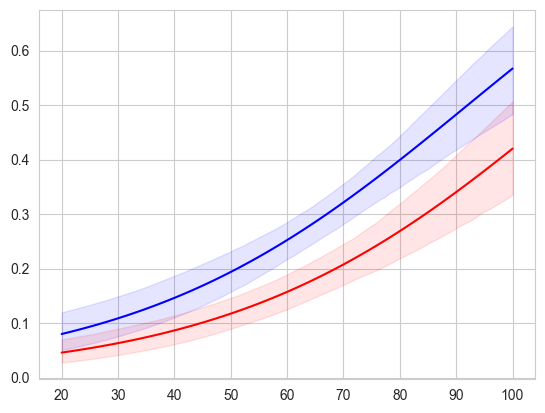

In [42]:
# This function plots confidence intervals for a set of bootstrapped intercepts and coefficients.
# You also have to provide the values on the x_axis, and a colour scheme.

def plot_CI(int_bs, coef_bs, X, color):
    CI = np.percentile(logistic(int_bs.T + coef_bs.T @ X), [2.5, 97.5], axis=0)
    plt.fill_between(X[0], CI[0], CI[1], color=color, alpha=0.1)


ages = np.linspace(20, 100, 100)
X_male_ci = np.vstack([ages, np.ones(ages.shape)]).T
X_female_ci = np.vstack([ages, np.zeros(ages.shape)]).T

probs_male_ci = logistic(model.intercept_ + X_male_ci @ model.coef_.T)
probs_female_ci = logistic(model.intercept_ + X_female_ci @ model.coef_.T)

plt.figure()
plot_CI(int_bs, coef_bs, X_male_ci.T, 'blue')
plot_CI(int_bs, coef_bs, X_female_ci.T, 'red')
plt.plot(ages, probs_male_ci, color='blue')
plt.plot(ages, probs_female_ci, color='red')
plt.show()

### Question 3.1: What can you conclude from this graph. What does it mean that the confidence intervals don't overlap?

Non-overlapping confidence intervals suggest significant differences in severity risk between groups (e.g., males vs. females).


***
## Part 4: Add `GGO` and `Consolidation`  

The previous model only explored the `sex` and `age` effect. In this part, we are going to add the `GGO` and `Consolidation` to the model.

### Task 4.1.

Similar to the code provided in Part 2, retrain the model on all 4 features. Print the coefficients and intercept.

In [43]:
# Your code here
X_all = df[['Age', 'Sex', 'GGO', 'Consolidation']]
model_all = LogisticRegression().fit(X_all, y)
print('New Coefficients:', model_all.coef_)
print('New Intercept:', model_all.intercept_)

New Coefficients: [[0.03558446 0.45909285 3.39938488 3.48334911]]
New Intercept: [-4.30087647]


### Question 4.1: The shape of the coefficient vector has changed, what do the values represent? Based on these values, what feature do you expect to have the highest impact on disease severity?
there are now 4 features, so for coefficients, one for each of them. the GGO and Consolidation have the highest values (Consolidation is higher), so they are expected to have the highest impact on disease severity. BUUUUUUT this is not fully valid since the values are not normalized, so the impact of each feature is not directly comparable.
Below i added the normalized one. but same holds true.

In [44]:
# NORMALIZED
# X_all = df[['Age', 'Sex', 'GGO', 'Consolidation']]
# X_all = (X_all - X_all.min()) / (X_all.max()-X_all.min())
# model_all = LogisticRegression().fit(X_all, y)
# print('New Coefficients:', model_all.coef_)
# print('New Intercept:', model_all.intercept_)

# New Coefficients: [[1.72431422 0.43746594 2.74818131 3.35807377]]
# New Intercept: [-3.08883738]

### Task 4.2: Use the bootstrapping technique to create the confidence interval for the new model

In [45]:
# Your code here
coef_bs_1 = np.zeros((4, N_bs))
int_bs_1 = np.zeros((1, N_bs))

for i in range(N_bs):
    sample = df.sample(n=len(df), replace=True)
    X_sample = sample[['Age', 'Sex', 'GGO', 'Consolidation']]
    y_sample = sample['Severity']
    model_bs = LogisticRegression().fit(X_sample, y_sample)
    coef_bs_1[:, i] = model_bs.coef_.flatten()
    int_bs_1[:, i] = model_bs.intercept_

### Tasks 4.3: Visualize the results of ```consolidation``` and ```GGO```:
As we now have multi-dimensional and continous data, we have to apply some tricks to plot the results.
Firstly, to reduce the dimensionality, we will only focus on males.
Secondly, a logistic regression model is a linear model, we can simply average out features.

Furthermore, ```consolidation``` and ```GGO``` are continous values. To assess their full impact, we will use the 10th and 90th percentiles. This reflects a 'High' or 'Low' value of ```consolidation``` and ```GGO```

__Hint 1:__ Create `X` such that you only have males.

__Hint 2:__ Set the ```GGO``` value to its mean in ```X``` when inspecting the impact of ```consolidation``` and vise versa.

__Hint 3:__ To create 2 plots, use the 10th and 90th percentile values in ```X``` for the feature of interest. (with `np.percenile`).

__Hint 4:__ You do not need to have the pointplots here as we do not have cathegorical data for the ```GGO``` and ```consolidation```.


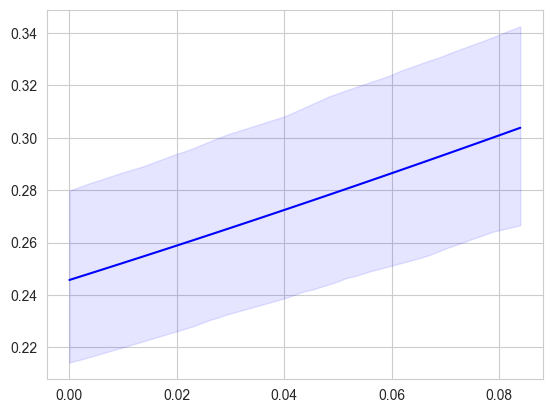

In [46]:
# Code for impact of Consolidation
def plot_CI(int_bs, coef_bs, X, color, i):
    CI = np.percentile(logistic(coef_bs.T @ X + int_bs.T), [2.5, 97.5], axis=0)
    plt.fill_between(X[i], CI[0], CI[1], color=color, alpha=0.1)

l = 100
temp = np.linspace(*np.percentile(df['Consolidation'], [10, 90]), l)
X_male_ci = np.vstack([np.ones(l) * np.mean(df_male['Age']), np.ones(l), np.ones(l) * np.mean(df_male['GGO']), temp]).T
probs_male_ci = logistic(X_male_ci @ model_all.coef_.T + model_all.intercept_)

plt.figure()
plot_CI(int_bs_1, coef_bs_1, X_male_ci.T, 'blue', 3)
plt.plot(temp, probs_male_ci, color='blue')
plt.show()

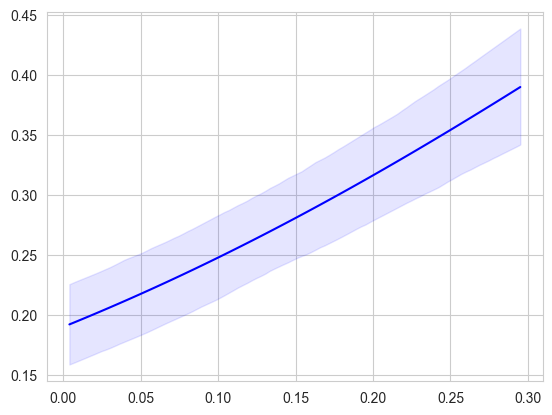

In [47]:
# Code for impact of GGO
def plot_CI(int_bs, coef_bs, X, color, i):
    CI = np.percentile(logistic(coef_bs.T @ X + int_bs.T), [2.5, 97.5], axis=0)
    plt.fill_between(X[i], CI[0], CI[1], color=color, alpha=0.1)

l = 100
temp = np.linspace(*np.percentile(df['GGO'], [10, 90]), l)
X_male_ci = np.vstack([np.ones(l) * np.mean(df_male['Age']), np.ones(l), temp, np.ones(l) * np.mean(df_male['Consolidation'])]).T
probs_male_ci = logistic(X_male_ci @ model_all.coef_.T + model_all.intercept_)

plt.figure()
plot_CI(int_bs_1, coef_bs_1, X_male_ci.T, 'blue', 2)
plt.plot(temp, probs_male_ci, color='blue')
plt.show()

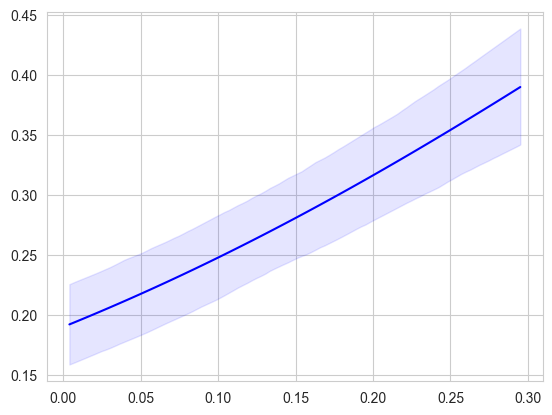

In [48]:
# Code for impact of GGO
def plot_CI(int_bs, coef_bs, X, color, i):
    CI = np.percentile(logistic(coef_bs.T @ X + int_bs.T), [2.5, 97.5], axis=0)
    plt.fill_between(X[i], CI[0], CI[1], color=color, alpha=0.1)

l = 100
temp = np.linspace(*np.percentile(df['GGO'], [10, 90]), l)
X_male_ci = np.vstack([np.ones(l) * np.mean(df_male['Age']), np.ones(l), temp, np.ones(l) * np.mean(df_male['Consolidation'])]).T
probs_male_ci = logistic(X_male_ci @ model_all.coef_.T + model_all.intercept_)

plt.figure()
plot_CI(int_bs_1, coef_bs_1, X_male_ci.T, 'blue', 2)
plt.plot(temp, probs_male_ci, color='blue')
plt.show()

### Question 4.2: What can you say on the impact on severity from `GGO` and `Consolidation`? Which one has the highest impact ?
GGO seems to have a more significant impact on severity since the severity changes than if Consolidation was moved. this seems counter to what was understood from coefficient.
Also, the confidence interval is reasonably small.


In [49]:
# Solution
#There is no additional risk increase due to consolidation for age and GGO fixed.

#Effect of GGO on severity risk is large, approximately 50% increase for people of 60 years old.
# This is larger than the age effect, which is lower than 40% in the whole range of age.

### Question 4.3: Does this insight agrees with your answer to Q3.1? Why could this happen?
__Hint:__ Have a look at the density plots you made in Part 1.
first assumption is wrong as the graph above shows a clear increase of risk with increase of consolidation.

for the second im lost. The below graphs shows a much higher change for age compared to Consolidation (for age of 60) which seems wrong to me.
The density of GGO (for non-severe cases) is much lower for small values of GGO relative to the density of Consolidation (for non-severe cases). This means that the impact of GGO on severity is more significant than the impact of Consolidation. 



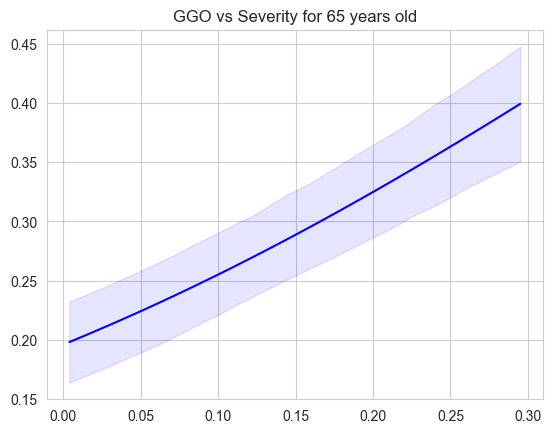

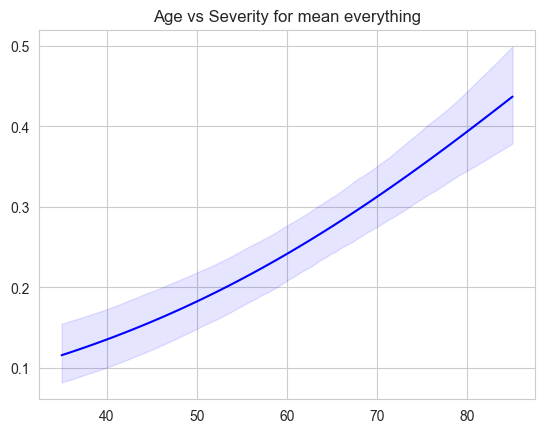

In [50]:
# Code for impact of GGO
l = 100
temp = np.linspace(*np.percentile(df['GGO'], [10, 90]), l)
X_male_ci = np.vstack([np.ones(l) * 65, np.ones(l), temp, np.ones(l) * np.mean(df_male['Consolidation'])]).T
probs_male_ci = logistic(X_male_ci @ model_all.coef_.T + model_all.intercept_)

plt.figure()
plot_CI(int_bs_1, coef_bs_1, X_male_ci.T, 'blue', 2)
plt.plot(temp, probs_male_ci, color='blue')
plt.title('GGO vs Severity for 65 years old')
plt.show()


l = 100
temp = np.linspace(*np.percentile(df['Age'], [0, 100]), l)
X_male_ci = np.vstack([temp, np.ones(l), np.ones(l) * np.mean(df_male['GGO']), np.ones(l) * np.mean(df_male['Consolidation'])]).T
probs_male_ci = logistic(X_male_ci @ model_all.coef_.T + model_all.intercept_)

plt.figure()
plot_CI(int_bs_1, coef_bs_1, X_male_ci.T, 'blue', 0)
plt.plot(temp, probs_male_ci, color='blue')
plt.title('Age vs Severity for mean everything')
plt.show()

## Part 5: Cost functions

After extracting knowledge from the data, it is time to put the logistic regression models into action.

You are working in an insurance company, and you have to advice the government what kind of financial model they should use to treat COVID-19 patients. The two options on the table are the logistic regression models trained on 2 (i.e. ```Age``` and ```Sex```) or on 4 features (i.e. ```Age```, ```Sex```, ```GGO```, ```Consolidation```).

Use decision curve analysis to investigate the 2 options.

__Hint 1:__ As you will now use the models to make predictions, it is necessary to split your dataset in a train and test split. Use `sklearn` for this and use a test split of size 33%.

__Hint 2:__ First, train your logistic regression model on 2 and later on 4 features. Use ```sklearn``` function ```predict_proba()``` to get probability values for your ```X```.

__Hint 3:__ Use the ```NetBenefitDisplay``` function from the ```statkit``` package to plot the curves.



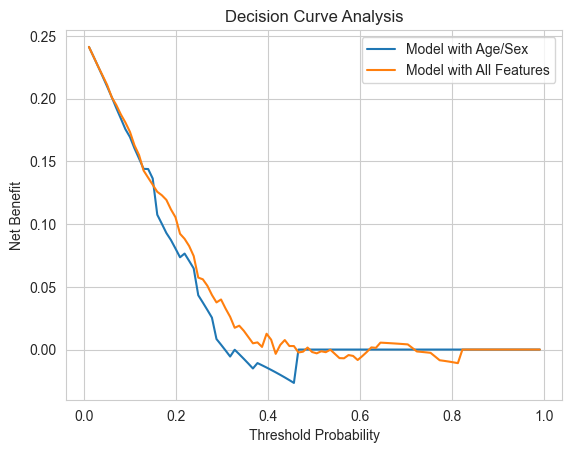

In [58]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Split data into train and test sets
X = df[['Age', 'Sex', 'GGO', 'Consolidation']]
y = df['Severity']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

# Train the two models
# Model 1: Only Age and Sex
model_2feat = LogisticRegression().fit(X_train[['Age', 'Sex']], y_train)
probs_2feat = model_2feat.predict_proba(X_test[['Age', 'Sex']])[:, 1]

# Model 2: All 4 features
model_4feat = LogisticRegression().fit(X_train, y_train)
probs_4feat = model_4feat.predict_proba(X_test)[:, 1]

# Define a function to compute net benefit
def calculate_net_benefit(y_true, y_pred_proba, thresholds):
    net_benefits = []
    for threshold in thresholds:
        y_pred = (y_pred_proba >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        n = len(y_true)
        net_benefit = (tp / n) - (fp / n) * (threshold / (1 - threshold))
        net_benefits.append(net_benefit)
    return np.array(net_benefits)

# Generate thresholds and compute net benefits
thresholds = np.linspace(0.01, 0.99, 100)
nb_2feat = calculate_net_benefit(y_test, probs_2feat, thresholds)
nb_4feat = calculate_net_benefit(y_test, probs_4feat, thresholds)

# Plot decision curves
plt.plot(thresholds, nb_2feat, label='Model with Age/Sex')
plt.plot(thresholds, nb_4feat, label='Model with All Features')
plt.xlabel('Threshold Probability')
plt.ylabel('Net Benefit')
plt.legend()
plt.title('Decision Curve Analysis')
plt.show()

### Question 5.1: What model would you advice to use. Explain with the help of the curves

In [52]:
# Your answer here...
# the 4 feature one seems better as it has a higher net benefit for all thresholds. interestingly though, not by much.